# My Question: 
# If a badminton player has a 65% success rate on their smash shots and attempts 12 smashes during a match, what is the probability that 9 of those smashes result in a winning point?

# Description:
## Random variable X in my simulation is the number of smash shots that are successful in resulting in a winning point. X can take discrete values from 0-12, however this simulation will be around the discrete value of 9 as that is the number of smash shots that need to be successful.
## One trial in this simulation would be a badminton player attempting to make 12 smash shots in a game for a winning point. Some possible outcomes would be that they miss the first three shots but get nine successful shots after those 3.

# Analysis

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

In [34]:
n = 12 

In [35]:
p = 0.65

In [36]:
simulations = 100_000

In [45]:
np.random.seed(200)

In [46]:
raw_data = np.random.binomial(n=1, p=p, size=(simulations, n))

In [47]:
df = pd.DataFrame(raw_data, columns=[f"Smash_{i+1}" for i in range(n)])

In [48]:
df["successes"] = df.sum(axis=1)

In [49]:
df["9"] = df["successes"] == 9

In [50]:
sim_prob = df["9"].mean()

In [51]:
exact_prob = stats.binom.pmf(9, n, p)

In [52]:
print(f"simulated probability (exactly 9 smashes): {sim_prob:.2%}")
print(f"Exact Binomial Probability:               {exact_prob:.2%}")

simulated probability (exactly 9 smashes): 19.48%
Exact Binomial Probability:               19.54%


## Simulated Bionomial Probability: 19.5%
## Theoretical Probability: 19.5%

In [53]:
mean_theory = stats.binom.mean(n, p) 

In [54]:
std_theory = stats.binom.std(n, p)

In [55]:
print(f"Theoretical Mean: {mean_theory:.4f}")
print(f"Theoretical Std Dev: {std_theory:.4f}")

Theoretical Mean: 7.8000
Theoretical Std Dev: 1.6523


In [56]:
mean_sim_np = np.mean(simulations)

In [57]:
std_sim_np = np.std(simulations)

In [58]:
mean_sim_pd = df["successes"].mean()

In [59]:
std_sim_pd = df["successes"].std()

In [60]:
print(f"Simulated Mean (Pandas): {mean_sim_pd:.4f}")
print(f"Simulated Std Dev (Pandas): {std_sim_pd:.4f}")

Simulated Mean (Pandas): 7.7991
Simulated Std Dev (Pandas): 1.6576


## Theoretical Mean: 7.800
## Simulated Mean: 7.801
## Theoretical STD: 1.652
## Simulated STD: 1.655

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

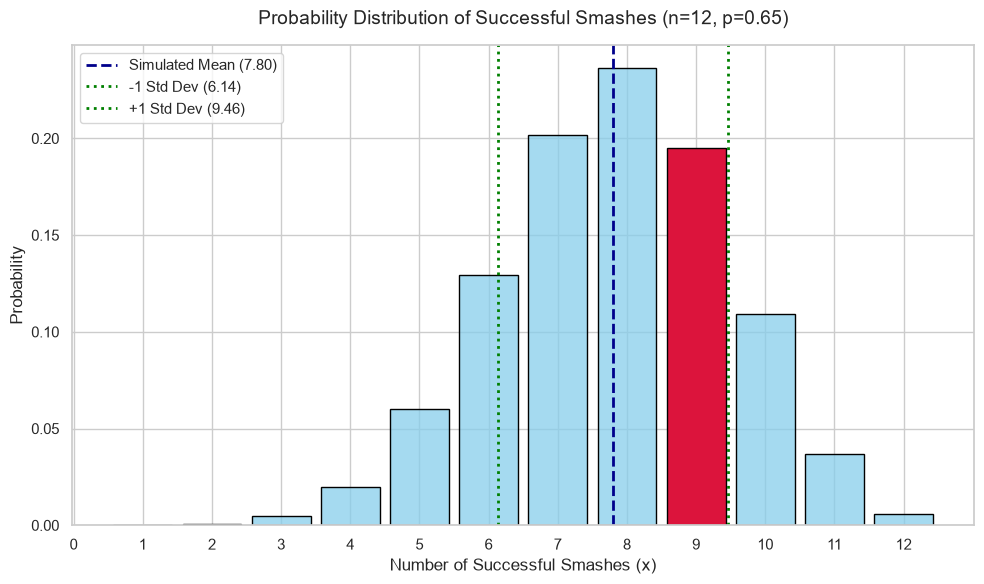

In [62]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


ax = sns.histplot(
    data=df,
    x="successes",
    stat="probability",
    discrete=True,
    color="skyblue",
    edgecolor="black",
    shrink=0.85,
)


bars = ax.patches
for bar in bars:
    if round(bar.get_x() + bar.get_width() / 2) == 9:
        bar.set_facecolor("crimson")


mean_sim = df["successes"].mean()
std_sim = df["successes"].std()


plt.axvline(
    mean_sim,
    color="darkblue",
    linestyle="--",
    linewidth=2,
    label=f"Simulated Mean ({mean_sim:.2f})",
)
plt.axvline(
    mean_sim - std_sim,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"-1 Std Dev ({mean_sim - std_sim:.2f})",
)
plt.axvline(
    mean_sim + std_sim,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"+1 Std Dev ({mean_sim + std_sim:.2f})",
)


plt.title(
    "Probability Distribution of Successful Smashes (n=12, p=0.65)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Number of Successful Smashes (x)", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.xticks(range(0, 13))
plt.legend(fontsize=11, loc="upper left")

plt.tight_layout()
plt.show()

# Conclusion:
## The theoretical and empirical probability of a badminton player making 9 of their 12 smash shots with a 65% success rate is 19.5.
## This graph supports my answer as it shows the mean(7.80) and the STD which in 1.65 in the simulation. These values match the theoretical probability of this siutation as well proving that this siutation
##
## 